# Ejercicio 3: Descenso de Gradiente con Momento
**Matemáticas para Inteligencia Artificial**

Función objetivo (en una variable):
$$f(x) = \frac{1}{4}x^4 - 2x^2$$

Con los datos del ejercicio:
$$\gamma = 0.05, \quad \alpha = 0.5, \quad x_0 = 1$$

Regla de actualización con momento:
$$x_{i+1} = x_i - \gamma f'(x_i) + \alpha \Delta x_i, \quad \text{donde } \Delta x_i = x_i - x_{i-1} \quad (\Delta x_0 = 0)$$

En este notebook comprobaremos:
1. La función $f(x)$, su primera derivada $f'(x)$ y su segunda derivada $f''(x)$.
2. Los puntos estacionarios ($f'(x) = 0$) y su clasificación como mínimos o máximos.
3. La tabla de las primeras 3 iteraciones ($x_0, x_1, x_2, x_3$) para validar los cálculos a mano.
4. La ejecución completa hasta alcanzar el mínimo ($|f'(x_i)| < 10^{-6}$).


## 1. Importación de librerías y datos del problema


In [1]:
import numpy as np              # Para cálculos numéricos y encontrar raíces
import pandas as pd             # Para mostrar los resultados en forma de tabla
import matplotlib.pyplot as plt # Para graficar el descenso de la función

# Parámetros del descenso de gradiente con momento
gamma = 0.05                    # Tasa de aprendizaje
alpha = 0.5                     # Factor de momento
x0 = 1.0                        # Punto inicial
tolerancia = 1e-6               # Criterio de paro: |f'(x_i)| < 10^-6
max_iteraciones = 1000          # Límite de seguridad para evitar ciclos infinitos

print("Tasa de aprendizaje (gamma):", gamma)
print("Momento (alpha):", alpha)
print("Punto inicial (x0):", x0)

Tasa de aprendizaje (gamma): 0.05
Momento (alpha): 0.5
Punto inicial (x0): 1.0


## 2. Definición de la función y sus derivadas


In [2]:
# Función objetivo: f(x) = (1/4)*x^4 - 2*x^2
def f(x):
    return 0.25 * (x**4) - 2.0 * (x**2)

# Inciso 1: Primera derivada f'(x) = x^3 - 4*x
def df(x):
    return (x**3) - 4.0 * x

# Segunda derivada f''(x) = 3*x^2 - 4 (para clasificar puntos estacionarios)
def d2f(x):
    return 3.0 * (x**2) - 4.0

# Probamos la evaluación en el punto inicial x0 = 1
print(f"En x0 = {x0}: f(x0) = {f(x0)}, f'(x0) = {df(x0)}, f''(x0) = {d2f(x0)}")

En x0 = 1.0: f(x0) = -1.75, f'(x0) = -3.0, f''(x0) = -1.0


## 3. Puntos estacionarios y clasificación con la segunda derivada


In [3]:
# Inciso 2: Encontrar las raíces de f'(x) = x^3 + 0*x^2 - 4*x + 0 = 0
coeficientes_df = [1, 0, -4, 0]
puntos_estacionarios = np.sort(np.roots(coeficientes_df))

print("Puntos estacionarios encontrados (f'(x) = 0):", puntos_estacionarios)
print("\nInciso 3: Clasificación usando f''(x) = 3x^2 - 4")

# Evaluamos cada punto estacionario en f(x) y f''(x)
for p in puntos_estacionarios:
    segunda_derivada = d2f(p)
    valor_f = f(p)
    
    if segunda_derivada > 0:
        tipo = "MÍNIMO"
    elif segunda_derivada < 0:
        tipo = "MÁXIMO"
    else:
        tipo = "Punto de inflexión / indeterminado"
        
    print(f"  x = {p:5.1f} | f(x) = {valor_f:5.1f} | f''(x) = {segunda_derivada:5.1f} -> {tipo}")

Puntos estacionarios encontrados (f'(x) = 0): [-2.  0.  2.]

Inciso 3: Clasificación usando f''(x) = 3x^2 - 4
  x =  -2.0 | f(x) =  -4.0 | f''(x) =   8.0 -> MÍNIMO
  x =   0.0 | f(x) =   0.0 | f''(x) =  -4.0 -> MÁXIMO
  x =   2.0 | f(x) =  -4.0 | f''(x) =   8.0 -> MÍNIMO


## 4. Ejecución del algoritmo de Descenso de Gradiente con Momento


In [4]:
# Inicializamos el punto actual con x0 y el desplazamiento anterior en 0
x = x0
delta_x = 0.0

# Lista para guardar los datos de cada iteración
historial = []

for i in range(max_iteraciones):
    # Calculamos la derivada (gradiente en 1D), su magnitud y el valor de la función
    derivada = df(x)
    norma_grad = abs(derivada)
    valor_f = f(x)
    
    # Guardamos los datos de la iteración actual (incluyendo Delta x_i)
    historial.append({
        "i": i,
        "x_i": x,
        "Delta x_i": delta_x,
        "f'(x_i)": derivada,
        "|f'(x_i)|": norma_grad,
        "f(x_i)": valor_f
    })
    
    # Criterio de paro: si |f'(x_i)| es menor a la tolerancia, terminamos
    if norma_grad < tolerancia:
        break
    
    # Regla de actualización con momento: x_{i+1} = x_i - gamma * f'(x_i) + alpha * Delta x_i
    x_siguiente = x - gamma * derivada + alpha * delta_x
    
    # Actualizamos el desplazamiento para la siguiente iteración: Delta x_{i+1} = x_{i+1} - x_i
    delta_x = x_siguiente - x
    x = x_siguiente

# Convertimos el historial en un DataFrame de pandas para verlo como tabla
tabla = pd.DataFrame(historial)

## 5. Comprobación de la tabla a mano (iteraciones $x_0$ a $x_3$)


In [5]:
# Mostramos solo las primeras 4 filas (i = 0, 1, 2, 3) para comparar con los cálculos a mano
tabla_a_mano = tabla[["i", "x_i", "Delta x_i", "f'(x_i)", "f(x_i)"]].head(4)
tabla_a_mano

,i,x_i,Delta x_i,f'(x_i),f(x_i)
0,0,1.000000,0.000000,-3.000000,-1.750000
1,1,1.150000,0.150000,-3.079125,-2.207748
2,2,1.378956,0.228956,-2.893712,-2.899096
3,3,1.638120,0.259164,-2.156688,-3.566665


## 6. Reporte del mínimo encontrado en Python


In [6]:
# Tomamos la última fila de la tabla, que corresponde al punto de convergencia
resultado = tabla.iloc[-1]
derivada_final = resultado["f'(x_i)"]
norma_final = resultado["|f'(x_i)|"]

print("=== RESULTADO FINAL ===")
print(f"Iteraciones totales:   {int(resultado['i'])}")
print(f"Mínimo encontrado x*:  {resultado['x_i']:.6f}")
print(f"Valor mínimo f(x*):    {resultado['f(x_i)']:.6f}")
print(f"Derivada final f'(x*): {derivada_final:.2e}")
print(f"Magnitud |f'(x*)|:     {norma_final:.2e}")

=== RESULTADO FINAL ===
Iteraciones totales:   46
Mínimo encontrado x*:  2.000000
Valor mínimo f(x*):    -4.000000
Derivada final f'(x*): 1.05e-07
Magnitud |f'(x*)|:     1.05e-07


## 7. Gráfica de convergencia de $f(x_i)$


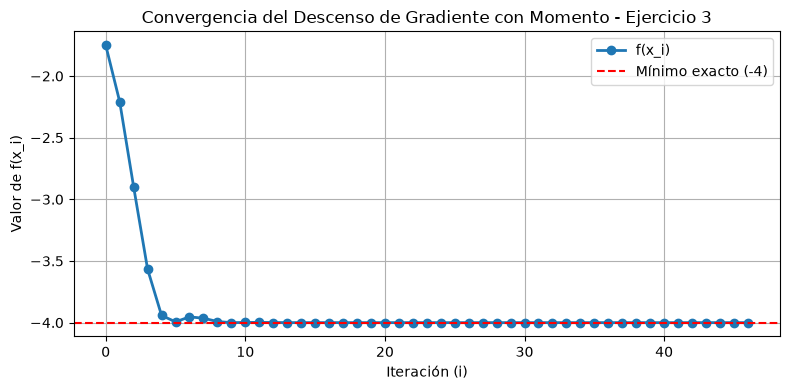

In [7]:
# Graficamos cómo disminuye f(x_i) en cada iteración hasta llegar al mínimo exacto (-4)
plt.figure(figsize=(8, 4))
plt.plot(tabla["i"], tabla["f(x_i)"], marker="o", linewidth=2, label="f(x_i)")
plt.axhline(-4.0, color="red", linestyle="--", label="Mínimo exacto (-4)")

plt.title("Convergencia del Descenso de Gradiente con Momento - Ejercicio 3")
plt.xlabel("Iteración (i)")
plt.ylabel("Valor de f(x_i)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()